<a href="https://colab.research.google.com/github/edbajric/winter-smog-sarajevo-almaty-visualisation/blob/main/BigDataCW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Data preprocessing**

In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt





# step 1: download the raw hourly data for both cities from open-meteo
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"Sarajevo": "#1f77b4", "Almaty": "#d62728"}

START, END = "2025-11-01", "2026-02-28"
CITIES = {
    "Sarajevo": {"lat": 43.8563, "lon": 18.4131, "tz": "Europe/Sarajevo", "domain": "cams_europe"},
    "Almaty":   {"lat": 43.2389, "lon": 76.8897, "tz": "Asia/Almaty",     "domain": "cams_global"},
}
CITY_ORDER = ["Sarajevo", "Almaty"]

# pollution variables from the air quality api
AQ_VARS = ["pm2_5", "pm10", "carbon_monoxide", "nitrogen_dioxide", "nitrogen_monoxide",
           "sulphur_dioxide", "ozone", "dust", "european_aqi", "us_aqi"]

# weather variables, these explain why smog builds up (wind, mixing height, temp)
WX_VARS = ["temperature_2m", "wind_speed_10m", "boundary_layer_height",
           "wind_direction_10m", "wind_gusts_10m", "relative_humidity_2m", "dew_point_2m",
           "pressure_msl", "precipitation", "snowfall", "snow_depth", "cloud_cover",
           "cloud_cover_low", "shortwave_radiation", "soil_temperature_0_to_7cm", "is_day"]
FEATURES = AQ_VARS + WX_VARS


# small helper that calls the api and turns the json into a dataframe
def fetch(url, params):
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    df = pd.DataFrame(r.json()["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    return df


# get air quality + weather for one city and join them on time
def load_city(name, c):
    common = {"latitude": c["lat"], "longitude": c["lon"],
              "start_date": START, "end_date": END, "timezone": c["tz"]}
    # sarajevo uses cams_europe (finer grid), almaty only has cams_global
    aq = fetch("https://air-quality-api.open-meteo.com/v1/air-quality",
               {**common, "hourly": ",".join(AQ_VARS), "domains": c["domain"]})
    wx = fetch("https://archive-api.open-meteo.com/v1/archive",
               {**common, "hourly": ",".join(WX_VARS)})
    # outer join so we dont lose any hours if one api is missing some
    df = aq.merge(wx, on="time", how="outer")
    df.insert(0, "city", name)
    return df


# stack both cities into one table and save a raw copy before changing anything
raw = pd.concat([load_city(n, c) for n, c in CITIES.items()], ignore_index=True)
raw.to_csv("raw_data.csv", index=False)
print("Raw shape:", raw.shape)
raw.head()




Raw shape: (5760, 28)


,city,time,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,nitrogen_monoxide,sulphur_dioxide,ozone,dust,...,dew_point_2m,pressure_msl,precipitation,snowfall,snow_depth,cloud_cover,cloud_cover_low,shortwave_radiation,soil_temperature_0_to_7cm,is_day
0,Sarajevo,2025-11-01 00:00:00,18.4,21.4,192.0,4.9,0.0,2.1,55.0,0.0,...,7.7,1021.0,0.0,0.0,0.0,0,0,0.0,10.3,0
1,Sarajevo,2025-11-01 01:00:00,14.6,16.9,175.0,3.3,0.0,2.5,51.0,0.0,...,6.7,1021.2,0.0,0.0,0.0,0,0,0.0,8.9,0
2,Sarajevo,2025-11-01 02:00:00,13.9,15.8,163.0,2.9,0.0,3.2,51.0,0.0,...,6.3,1021.1,0.0,0.0,0.0,0,0,0.0,8.8,0
3,Sarajevo,2025-11-01 03:00:00,13.0,15.9,149.0,2.8,0.0,3.7,52.0,1.0,...,6.0,1020.8,0.0,0.0,0.0,0,0,0.0,8.6,0
4,Sarajevo,2025-11-01 04:00:00,12.1,14.7,145.0,2.4,0.0,4.0,53.0,1.0,...,5.8,1020.6,0.0,0.0,0.0,0,0,0.0,8.4,0


In [ ]:
# check the data types, everything should be numeric except city and time
print(raw.dtypes.value_counts())
non_numeric = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(raw[c])]
print("Non-numeric features:", non_numeric)
raw.info()

float64           19
int64              7
datetime64[ns]     1
object             1
Name: count, dtype: int64
Non-numeric features: []
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5760 entries, 0 to 5759
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   city                       5760 non-null   object        
 1   time                       5760 non-null   datetime64[ns]
 2   pm2_5                      5760 non-null   float64       
 3   pm10                       5760 non-null   float64       
 4   carbon_monoxide            5760 non-null   float64       
 5   nitrogen_dioxide           5760 non-null   float64       
 6   nitrogen_monoxide          5760 non-null   float64       
 7   sulphur_dioxide            5760 non-null   float64       
 8   ozone                      5760 non-null   float64       
 9   dust                       5760 non-null   float64       
 1

In [ ]:
# work on a copy so the raw data stays untouched
df = raw.copy()
# city as category saves memory and makes groupby faster
df["city"] = df["city"].astype("category")

In [ ]:
# check missing values per city
missing = df[FEATURES].isna().groupby(df["city"]).sum().T
print(missing[missing.sum(axis=1) > 0] if missing.values.sum() else "No missing values in any feature")
if missing.values.sum():
    # only fill short gaps (max 3 hours) and do it per city so values dont leak between cities
    df[FEATURES] = df.groupby("city")[FEATURES].transform(
        lambda s: s.interpolate(limit=3, limit_direction="both"))


No missing values in any feature


/tmp/ipykernel_1789/3403802182.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  missing = df[FEATURES].isna().groupby(df["city"]).sum().T


In [ ]:
# check for duplicate hours and that each city has all 2880 hours (120 days x 24)
dups = df.duplicated(["city", "time"]).sum()
expected = len(pd.date_range(START, f"{END} 23:00", freq="h"))
per_city = df.groupby("city").size()
print(f"Duplicates: {dups} | expected hours per city: {expected}")
print(per_city)
if dups:
    df = df.drop_duplicates(["city", "time"])

Duplicates: 0 | expected hours per city: 2880
city
Almaty      2880
Sarajevo    2880
dtype: int64


/tmp/ipykernel_1789/3109661707.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per_city = df.groupby("city").size()


In [ ]:
# range checks: anything physically impossible becomes nan. limits come from world records or definitions
limits = {
    **{c: (0, None) for c in AQ_VARS},          # def: concentrations/indices >= 0
    "temperature_2m":            (-89.2, 56.7), # wmo: vostok 1983 / death valley 1913
    "dew_point_2m":              (-89.2, 56.7), # phys: dew point <= air temp (checked below)
    "soil_temperature_0_to_7cm": (-89.2, 80),   # phys: ground can be hotter than air
    "wind_speed_10m":            (0, 408),      # def >= 0; wmo max gust as upper bound
    "wind_gusts_10m":            (0, 408),      # wmo: 113.2 m/s, barrow island 1996
    "wind_direction_10m":        (0, 360),      # def: compass degrees
    "relative_humidity_2m":      (0, 100),      # def: percentage
    "cloud_cover":               (0, 100),      # def: percentage
    "cloud_cover_low":           (0, 100),      # def: percentage
    "pressure_msl":              (870, 1089.1), # wmo: typhoon tip 1979 / tosontsengel 2004
    "precipitation":             (0, None),     # def: amount >= 0
    "snowfall":                  (0, None),     # def: amount >= 0
    "snow_depth":                (0, None),     # def: depth >= 0
    "shortwave_radiation":       (0, 1361),     # phys: solar constant (top of atmosphere)
    "boundary_layer_height":     (0, None),     # def: height >= 0
    "is_day":                    (0, 1),        # def: binary flag
}

def count_invalid(s, lo, hi):
    lo = -np.inf if lo is None else lo
    hi =  np.inf if hi is None else hi
    return ~s.between(lo, hi)

invalid = {c: int(count_invalid(df[c], lo, hi).sum()) for c, (lo, hi) in limits.items()}
print({k: v for k, v in invalid.items() if v} or "No impossible values")

# dew point can never be higher than air temperature (0.1 tolerance for rounding)
print("Dew point > temperature:", int((df.dew_point_2m > df.temperature_2m + 0.1).sum()))

# replace bad values with nan instead of deleting the whole row
for c, (lo, hi) in limits.items():
    df.loc[count_invalid(df[c], lo, hi), c] = np.nan

No impossible values
Dew point > temperature: 0


In [ ]:
# look at zeros, unique values and std to spot constant or weird columns
info = pd.DataFrame({"zeros_%": (df[FEATURES] == 0).mean() * 100,
                     "unique": df[FEATURES].nunique(),
                     "std": df[FEATURES].std()}).round(2)
print(info.sort_values("zeros_%", ascending=False).head(8))

                     zeros_%  unique     std
snowfall               94.31      25    0.12
precipitation          81.18      52    0.48
is_day                 59.79       2    0.49
shortwave_radiation    57.43     516  132.83
snow_depth             54.62      40    0.08
dust                   42.93      67    7.78
cloud_cover_low        31.01     101   42.13
nitrogen_monoxide      18.75     346    7.33


In [ ]:
# find feature pairs that are almost the same (corr > 0.9), they are redundant
corr = df[FEATURES].corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .loc[lambda s: s.abs() > 0.9].sort_values(ascending=False))
print(pairs.round(3))

pm2_5  pm10            0.981
       european_aqi    0.947
pm10   european_aqi    0.928
dtype: float64


/tmp/ipykernel_1789/3101381352.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = df.groupby("city")[AQ_VARS].agg(iqr_share).T.round(1)


% of hours flagged as outliers:
 city               Almaty  Sarajevo
pm2_5                 1.0       5.2
pm10                  0.8       5.3
carbon_monoxide       1.8       4.1
nitrogen_dioxide      0.1       4.9
nitrogen_monoxide     4.0      12.4
sulphur_dioxide       3.1       5.7
ozone                 0.3       0.2
dust                  6.0      21.7
european_aqi          2.9       3.1
us_aqi                4.7       0.0


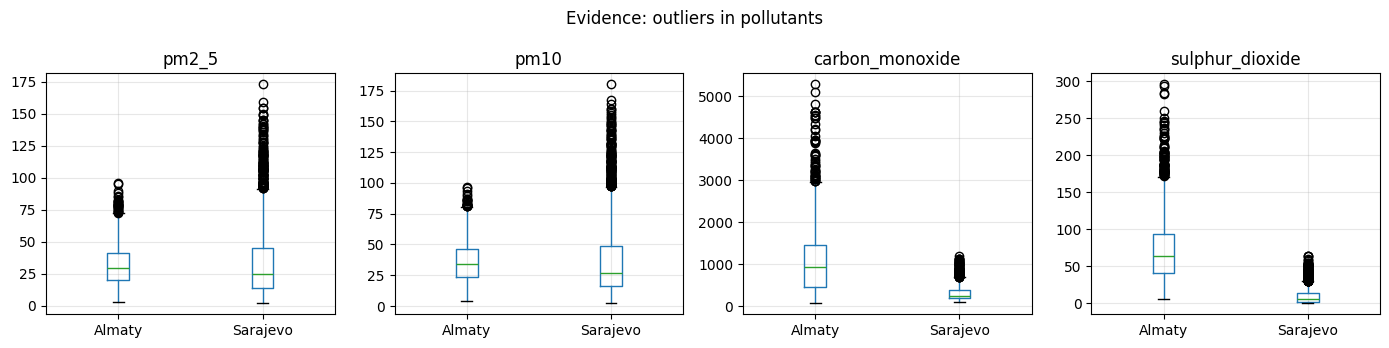

/tmp/ipykernel_1789/3101381352.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df["pm25_outlier"] = df.groupby("city")["pm2_5"].transform(


In [ ]:
# count outliers with the iqr rule (1.5 x iqr) per city
def iqr_share(s):
    q1, q3 = s.quantile([.25, .75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).mean() * 100

out = df.groupby("city")[AQ_VARS].agg(iqr_share).T.round(1)
print("% of hours flagged as outliers:\n", out)

# boxplots as evidence of the outliers
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, ["pm2_5", "pm10", "carbon_monoxide", "sulphur_dioxide"]):
    df.boxplot(column=col, by="city", ax=ax); ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Evidence: outliers in pollutants"); plt.tight_layout(); plt.show()
# flag outliers instead of deleting them, smog peaks are real events and the whole point of the project
df["pm25_outlier"] = df.groupby("city")["pm2_5"].transform(
    lambda s: s > s.quantile(.75) + 1.5 * (s.quantile(.75) - s.quantile(.25)))

snowfall                     13.10
precipitation                10.78
dust                          3.51
boundary_layer_height         3.03
nitrogen_monoxide             2.93
snow_depth                    2.41
wind_gusts_10m                2.05
carbon_monoxide               1.99
shortwave_radiation           1.71
pm2_5                         1.68
pm10                          1.59
sulphur_dioxide               1.49
wind_speed_10m                1.21
european_aqi                  0.73
us_aqi                        0.64
nitrogen_dioxide              0.58
cloud_cover_low               0.44
ozone                         0.30
soil_temperature_0_to_7cm     0.08
temperature_2m               -0.29
dew_point_2m                 -0.54
pressure_msl                 -0.61
relative_humidity_2m         -0.76
cloud_cover                  -0.80
dtype: float64
Log1p candidates: ['dust', 'boundary_layer_height', 'nitrogen_monoxide', 'wind_gusts_10m', 'carbon_monoxide', 'pm2_5', 'pm10', 'sulphur_dioxide',

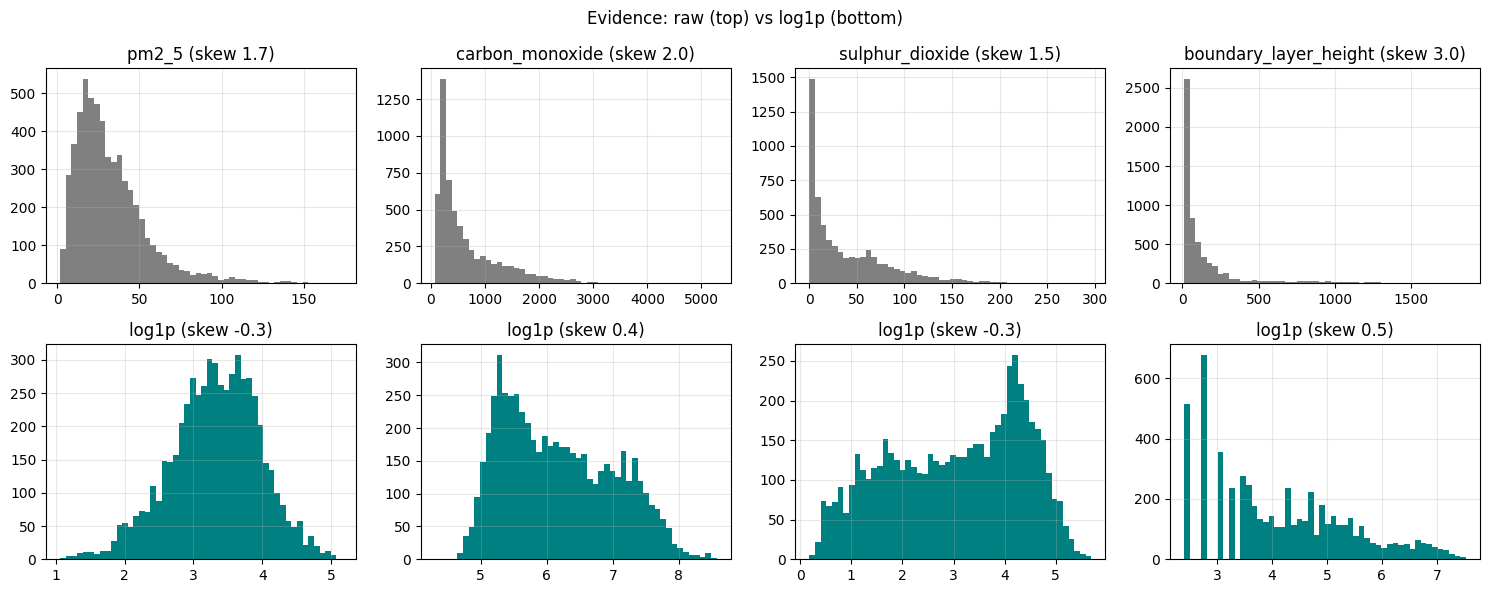

In [ ]:
# check skewness to decide which columns need a log transform
cont = [c for c in FEATURES if c not in ("is_day", "wind_direction_10m")]
skew = df[cont].skew().sort_values(ascending=False).round(2)
print(skew)

# columns with loads of zeros (snow, rain) dont work well with log so keep them separate
zeros = (df[cont] == 0).mean()
to_log = [c for c in skew.index[skew > 1] if (df[c] >= 0).all() and zeros[c] < 0.5]
zero_inflated = [c for c in skew.index[skew > 1] if zeros[c] >= 0.5]
print("Log1p candidates:", to_log)
print("Zero-inflated (flag instead of log):", zero_inflated)

# compare skew before and after log1p to show it actually helps
print(pd.DataFrame({"skew_raw": df[to_log].skew(),
                    "skew_log1p": np.log1p(df[to_log]).skew()}).round(2))

# histograms before (top) and after log1p (bottom)
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for i, col in enumerate(["pm2_5", "carbon_monoxide", "sulphur_dioxide", "boundary_layer_height"]):
    axes[0, i].hist(df[col], bins=50, color="grey"); axes[0, i].set_title(f"{col} (skew {df[col].skew():.1f})")
    axes[1, i].hist(np.log1p(df[col]), bins=50, color="teal")
    axes[1, i].set_title(f"log1p (skew {np.log1p(df[col]).skew():.1f})")
plt.suptitle("Evidence: raw (top) vs log1p (bottom)"); plt.tight_layout(); plt.show()

In [ ]:
# compare the range of each feature, they are on very different scales (co goes up to 5000, wind only 25)
cols = list(FEATURES)

scale = df[cols].agg(["min", "max", "mean", "std"]).T
scale["range"] = scale["max"] - scale["min"]
print(scale.sort_values("range", ascending=False).round(1))
print(f"Largest / smallest range ratio: "
      f"{scale['range'].max() / scale.loc[scale['range'] > 0, 'range'].min():,.0f}x")

                             min     max    mean    std   range
carbon_monoxide             73.0  5282.0   683.2  646.5  5209.0
boundary_layer_height       10.0  1860.0   154.2  253.3  1850.0
shortwave_radiation          0.0   655.0    78.5  132.8   655.0
wind_direction_10m           1.0   360.0   174.4  103.4   359.0
sulphur_dioxide              0.2   296.1    41.0   44.1   295.9
pm10                         2.2   180.1    36.4   23.5   177.9
pm2_5                        1.9   173.2    32.6   21.9   171.3
us_aqi                      35.0   165.0    95.8   24.3   130.0
ozone                       10.0   138.0    57.2   16.9   128.0
cloud_cover                  0.0   100.0    68.9   40.1   100.0
cloud_cover_low              0.0   100.0    39.9   42.1   100.0
european_aqi                18.0   113.0    49.9   13.5    95.0
wind_gusts_10m               1.4    82.4    14.8    7.9    81.0
dust                         0.0    80.0     4.3    7.8    80.0
relative_humidity_2m        24.0   100.0

In [ ]:
# share of total variance per feature, without scaling co alone would be ~80% of it
var_share = (df[cols].var() / df[cols].var().sum() * 100).sort_values(ascending=False)
print(var_share.round(1))

carbon_monoxide              80.6
boundary_layer_height        12.4
shortwave_radiation           3.4
wind_direction_10m            2.1
sulphur_dioxide               0.4
cloud_cover_low               0.3
cloud_cover                   0.3
us_aqi                        0.1
pm10                          0.1
pm2_5                         0.1
ozone                         0.1
relative_humidity_2m          0.0
nitrogen_dioxide              0.0
european_aqi                  0.0
pressure_msl                  0.0
wind_gusts_10m                0.0
dust                          0.0
nitrogen_monoxide             0.0
dew_point_2m                  0.0
temperature_2m                0.0
soil_temperature_0_to_7cm     0.0
wind_speed_10m                0.0
is_day                        0.0
precipitation                 0.0
snowfall                      0.0
snow_depth                    0.0
dtype: float64


      pm2_5  pm10  carbon_monoxide  nitrogen_dioxide  nitrogen_monoxide  \
mean   -0.0  -0.0              0.0              -0.0               -0.0   
std     1.0   1.0              1.0               1.0                1.0   

      sulphur_dioxide  ozone  dust  european_aqi  us_aqi  ...  dew_point_2m  \
mean              0.0    0.0   0.0           0.0     0.0  ...           0.0   
std               1.0    1.0   1.0           1.0     1.0  ...           1.0   

      pressure_msl  precipitation  snowfall  snow_depth  cloud_cover  \
mean           0.0           -0.0       0.0         0.0         -0.0   
std            1.0            1.0       1.0         1.0          1.0   

      cloud_cover_low  shortwave_radiation  soil_temperature_0_to_7cm  is_day  
mean              0.0                 -0.0                        0.0    -0.0  
std               1.0                  1.0                        1.0     1.0  

[2 rows x 26 columns]


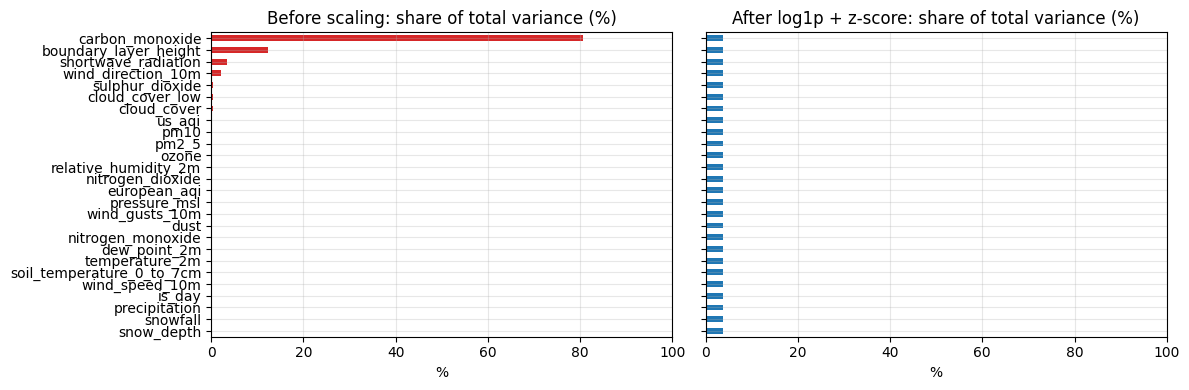

In [ ]:
# fix the scale problem: log1p on skewed columns, then z-score so every column has mean 0 and std 1
from sklearn.preprocessing import StandardScaler

cols = list(FEATURES)
LOG_COLS = ["boundary_layer_height", "carbon_monoxide", "pm2_5",
            "sulphur_dioxide", "wind_speed_10m"]

var_share = df[cols].var() / df[cols].var().sum() * 100

X = df[cols].copy()
# log1p instead of log because some values are 0
X[LOG_COLS] = np.log1p(X[LOG_COLS])
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X),
                        columns=cols, index=df.index)
print(X_scaled.agg(["mean", "std"]).round(2))

after = X_scaled.var() / X_scaled.var().sum() * 100

# before vs after plot, same order so its easy to compare
order = var_share.sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
var_share[order].plot.barh(ax=ax[0], color="#d62728")
ax[0].set_title("Before scaling: share of total variance (%)")
after[order].plot.barh(ax=ax[1], color="#1f77b4")
ax[1].set_title("After log1p + z-score: share of total variance (%)")
for a in ax:
    a.set_xlim(0, 100)
    a.set_xlabel("%")
plt.tight_layout()
plt.savefig("scaling_evidence.png", dpi=150)
plt.show()

In [ ]:
# wind direction is circular (359 and 1 degree are neighbours) so split it into sin and cos
rad = np.radians(df["wind_direction_10m"])
df["wind_dir_sin"], df["wind_dir_cos"] = np.sin(rad), np.cos(rad)

# when there is no wind the direction means nothing, so set both to 0
calm0 = df["wind_speed_10m"] == 0
df.loc[calm0, ["wind_dir_sin", "wind_dir_cos"]] = 0
print("Calm hours set to (0, 0):", int(calm0.sum()))

Calm hours set to (0, 0): 10


In [ ]:
# feature engineering: time features
df["date"]    = df["time"].dt.date
df["month"]   = df["time"].dt.strftime("%Y-%m")
df["hour"]    = df["time"].dt.hour
df["weekday"] = df["time"].dt.day_name()
df["is_weekend"] = df["time"].dt.day_of_week >= 5

# ratio and difference features, pm_ratio = how much of pm10 is fine particles
df["pm_ratio"]        = df["pm2_5"] / df["pm10"].replace(0, np.nan)
df["temp_minus_soil"] = df["temperature_2m"] - df["soil_temperature_0_to_7cm"]
df["dewpoint_spread"] = df["temperature_2m"] - df["dew_point_2m"]

# simple yes/no flags for conditions that trap smog
df["calm_wind"]      = df["wind_speed_10m"] < 5
df["low_blh"]        = df["boundary_layer_height"] < 100
df["below_zero"]     = df["temperature_2m"] < 0
df["is_precip"]      = df["precipitation"] > 0
df["has_snow_cover"] = df["snow_depth"] > 0
df["is_snowing"]     = df["snowfall"] > 0

# put pm2.5 into air quality bands so its easier to read
bins   = [0, 5, 15, 50, 90, 140, np.inf]
labels = ["Good", "Fair", "Moderate", "Poor", "Very poor", "Extremely poor"]
df["aqi_band"] = pd.cut(df["pm2_5"], bins=bins, labels=labels, right=False)
print(pd.crosstab(df["city"], df["aqi_band"], normalize="index").mul(100).round(1))

aqi_band  Good  Fair  Moderate  Poor  Very poor  Extremely poor
city                                                           
Almaty     0.3   9.6      78.2  11.8        0.1             0.0
Sarajevo   2.3  25.5      51.7  15.0        5.0             0.5


In [ ]:
# log the skewed engineered features too, then z-score everything into a separate scaled table
eng = ["pm_ratio", "temp_minus_soil", "dewpoint_spread"]
eng_skew = df[eng].skew()
print("Engineered skew:", eng_skew.round(2).to_dict())
to_log += [c for c in eng if eng_skew[c] > 1 and (df[c] >= 0).all()]

for c in to_log:
    df[f"log_{c}"] = np.log1p(df[c])

base = [c for c in FEATURES if c not in ("is_day", "wind_direction_10m")] + eng
scale_cols = [f"log_{c}" if c in to_log else c for c in base]

scaled = df[["city", "time", "wind_dir_sin", "wind_dir_cos"]].copy()
scaled[scale_cols] = (df[scale_cols] - df[scale_cols].mean()) / df[scale_cols].std()

# sanity check, mean should be 0 and std should be 1
check = scaled[scale_cols].agg(["mean", "std"]).T
print(f"mean range: {check['mean'].min():.3f} to {check['mean'].max():.3f} | "
      f"std range: {check['std'].min():.3f} to {check['std'].max():.3f}")


Engineered skew: {'pm_ratio': -1.98, 'temp_minus_soil': -0.36, 'dewpoint_spread': 1.49}
mean range: -0.000 to 0.000 | std range: 1.000 to 1.000


In [ ]:
# daily averages per city, needed to compare with the who 24h guideline (15 µg/m³)
daily = (df.groupby(["city", "date"])
           .agg(pm2_5=("pm2_5", "mean"), pm2_5_max=("pm2_5", "max"),
                pm10=("pm10", "mean"), so2=("sulphur_dioxide", "mean"),
                co=("carbon_monoxide", "mean"), no2=("nitrogen_dioxide", "mean"),
                temp=("temperature_2m", "mean"), wind=("wind_speed_10m", "mean"),
                blh=("boundary_layer_height", "mean"), pressure=("pressure_msl", "mean"),
                precip=("precipitation", "sum"), snow_depth=("snow_depth", "mean"))
           .reset_index())
daily["date"] = pd.to_datetime(daily["date"])
# true if that day was above the who limit
daily["who_exceed"] = daily["pm2_5"] > 15

/tmp/ipykernel_1789/2412111777.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  daily = (df.groupby(["city", "date"])


In [ ]:
# save the clean files so the visualisation part can just load them
df.to_csv("clean_hourly.csv", index=False)
scaled.to_csv("clean_hourly_scaled.csv", index=False)
daily.to_csv("clean_daily.csv", index=False)
print("clean_hourly:", df.shape, "| scaled:", scaled.shape, "| daily:", daily.shape)

clean_hourly: (5760, 56) | scaled: (5760, 31) | daily: (240, 15)


In [ ]:
# quick look at the clean data
df = pd.read_csv("clean_hourly.csv")
df.head()

,city,time,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,nitrogen_monoxide,sulphur_dioxide,ozone,dust,...,log_dust,log_boundary_layer_height,log_nitrogen_monoxide,log_wind_gusts_10m,log_carbon_monoxide,log_pm2_5,log_pm10,log_sulphur_dioxide,log_wind_speed_10m,log_dewpoint_spread
0,Sarajevo,2025-11-01 00:00:00,18.4,21.4,192.0,4.9,0.0,2.1,55.0,0.0,...,0.000000,3.258097,0.0,2.778819,5.262690,2.965273,3.109061,1.131402,1.887070,0.832909
1,Sarajevo,2025-11-01 01:00:00,14.6,16.9,175.0,3.3,0.0,2.5,51.0,0.0,...,0.000000,2.772589,0.0,2.803360,5.170484,2.747271,2.884801,1.252763,1.547563,0.832909
2,Sarajevo,2025-11-01 02:00:00,13.9,15.8,163.0,2.9,0.0,3.2,51.0,0.0,...,0.000000,3.044522,0.0,2.760010,5.099866,2.701361,2.821379,1.435085,1.856298,0.788457
3,Sarajevo,2025-11-01 03:00:00,13.0,15.9,149.0,2.8,0.0,3.7,52.0,1.0,...,0.693147,3.044522,0.0,2.803360,5.010635,2.639057,2.827314,1.547563,1.902108,0.641854
4,Sarajevo,2025-11-01 04:00:00,12.1,14.7,145.0,2.4,0.0,4.0,53.0,1.0,...,0.693147,3.258097,0.0,2.965273,4.983607,2.572612,2.753661,1.609438,2.128232,0.530628


Columns used: {'pm2_5': 'log_pm2_5', 'nitrogen_dioxide': 'nitrogen_dioxide', 'sulphur_dioxide': 'log_sulphur_dioxide', 'carbon_monoxide': 'log_carbon_monoxide', 'ozone': 'ozone', 'temperature_2m': 'temperature_2m', 'wind_speed_10m': 'log_wind_speed_10m', 'boundary_layer_height': 'log_boundary_layer_height', 'relative_humidity_2m': 'relative_humidity_2m', 'pressure_msl': 'pressure_msl'}
Daily rows per city: {'Almaty': 120, 'Sarajevo': 120}
PCA explained variance: PC1 50.3%, PC2 14.5%

Loadings:
            PC1   PC2
BLH      -0.34 -0.26
Wind     -0.32 -0.01
Temp     -0.27  0.26
RH       -0.20 -0.55
O3        0.12  0.61
PM2.5     0.27 -0.40
Pressure  0.31 -0.07
CO        0.40 -0.15
NO2       0.41  0.02
SO2       0.41 -0.06


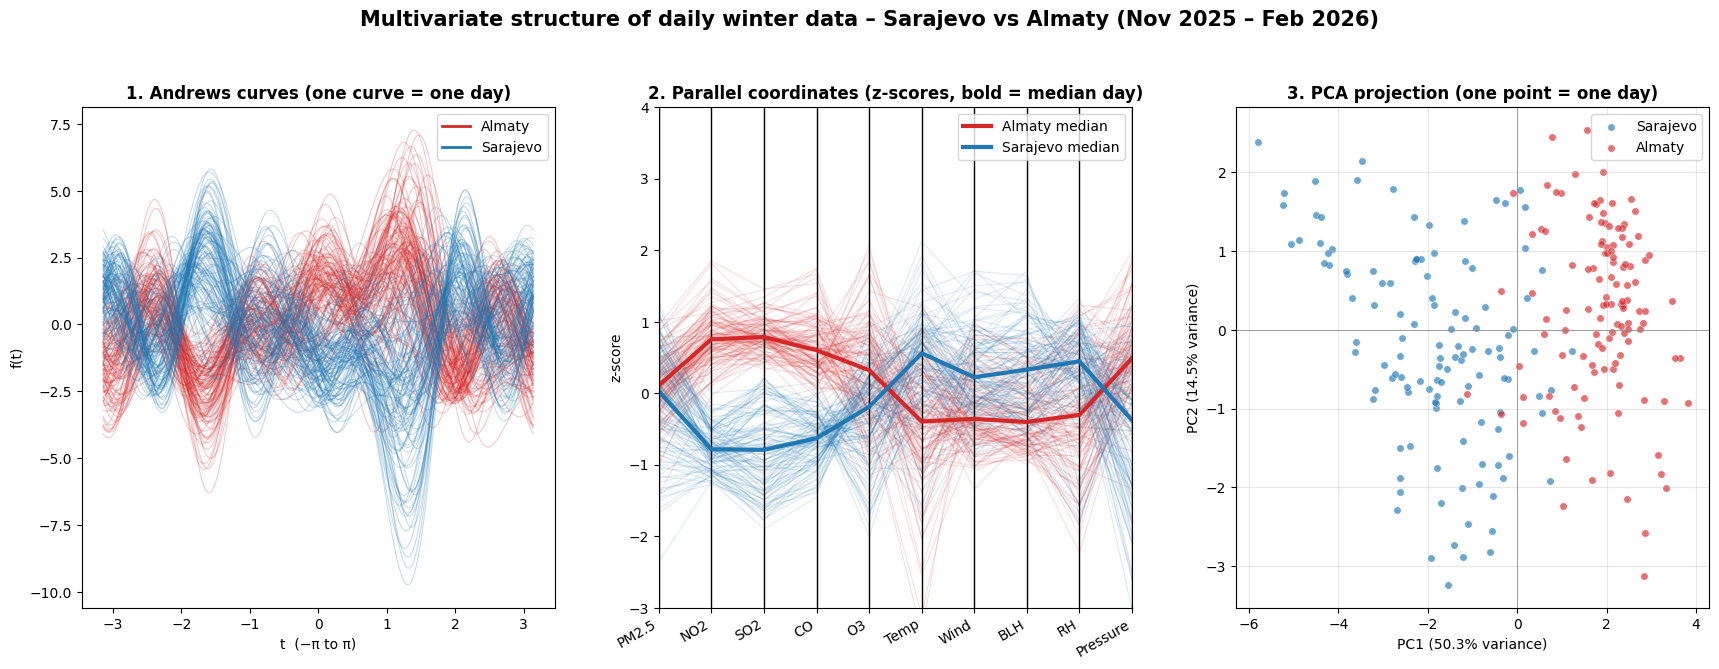


Saved multivariate_by_city.png


In [ ]:
# multivariate view: andrews curves, parallel coordinates and pca on daily data
from pandas.plotting import andrews_curves, parallel_coordinates
from sklearn.decomposition import PCA

COLORS = {"Sarajevo": "#1f77b4", "Almaty": "#d62728"}

PLOT_FEATURES = {
    "pm2_5": "PM2.5", "nitrogen_dioxide": "NO2", "sulphur_dioxide": "SO2",
    "carbon_monoxide": "CO", "ozone": "O3", "temperature_2m": "Temp",
    "wind_speed_10m": "Wind", "boundary_layer_height": "BLH",
    "relative_humidity_2m": "RH", "pressure_msl": "Pressure",
}

sc = pd.read_csv("clean_hourly_scaled.csv", parse_dates=["time"])
sc["date"] = sc["time"].dt.date

col = {f: (f"log_{f}" if f"log_{f}" in sc.columns else f) for f in PLOT_FEATURES}
missing = [c for c in col.values() if c not in sc.columns]
assert not missing, f"Not in clean_hourly_scaled.csv: {missing}"
print("Columns used:", col)

daily = (sc.groupby(["city", "date"])[list(col.values())].mean()
           .rename(columns={v: PLOT_FEATURES[k] for k, v in col.items()})
           .reset_index())
X = daily[list(PLOT_FEATURES.values())]
print("Daily rows per city:", daily["city"].value_counts().to_dict())


fig = plt.figure(figsize=(21, 6.5))
gs = fig.add_gridspec(1, 3, wspace=0.22)

ax1 = fig.add_subplot(gs[0, 0])
andrews_curves(daily[["city"] + list(X.columns)], "city", ax=ax1,
               color=[COLORS[c] for c in daily["city"].unique()], alpha=0.25, lw=0.8)
ax1.set_title("1. Andrews curves (one curve = one day)", fontweight="bold")
ax1.set_xlabel("t  (−π to π)"); ax1.set_ylabel("f(t)")
leg = ax1.legend(loc="upper right")
for l in leg.get_lines(): l.set_alpha(1); l.set_linewidth(2)

ax2 = fig.add_subplot(gs[0, 1])
parallel_coordinates(daily[["city"] + list(X.columns)], "city", ax=ax2,
                     color=[COLORS[c] for c in daily["city"].unique()], alpha=0.15, lw=0.8)
med = daily.groupby("city")[list(X.columns)].median()
for city, row in med.iterrows():
    ax2.plot(range(len(row)), row.values, color=COLORS[city], lw=3, label=f"{city} median")
ax2.set_title("2. Parallel coordinates (z-scores, bold = median day)", fontweight="bold")
ax2.set_ylabel("z-score"); ax2.set_ylim(-3, 4)
ax2.tick_params(axis="x", rotation=30)
for t in ax2.get_xticklabels(): t.set_ha("right")
h, l = ax2.get_legend_handles_labels()
ax2.legend(h[-2:], l[-2:], loc="upper right")


# standardise again on the daily data before pca
Xz = (X - X.mean()) / X.std()
pca = PCA(n_components=2).fit(Xz)
scores = pca.transform(Xz)
ev = pca.explained_variance_ratio_ * 100
print(f"PCA explained variance: PC1 {ev[0]:.1f}%, PC2 {ev[1]:.1f}%")

ax3 = fig.add_subplot(gs[0, 2])
for city, c in COLORS.items():
    m = (daily["city"] == city).values
    ax3.scatter(scores[m, 0], scores[m, 1], s=28, alpha=0.65, color=c,
                edgecolor="white", lw=0.4, label=city)
ax3.axhline(0, color="grey", lw=0.5); ax3.axvline(0, color="grey", lw=0.5)
ax3.set_xlabel(f"PC1 ({ev[0]:.1f}% variance)"); ax3.set_ylabel(f"PC2 ({ev[1]:.1f}% variance)")
ax3.set_title("3. PCA projection (one point = one day)", fontweight="bold")
ax3.legend()

load = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])
print("\nLoadings:\n", load.round(2).sort_values("PC1"))

fig.suptitle("Multivariate structure of daily winter data – Sarajevo vs Almaty (Nov 2025 – Feb 2026)",
             fontsize=15, fontweight="bold", y=1.03)
plt.savefig("multivariate_by_city.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved multivariate_by_city.png")

# **Data visualisation**

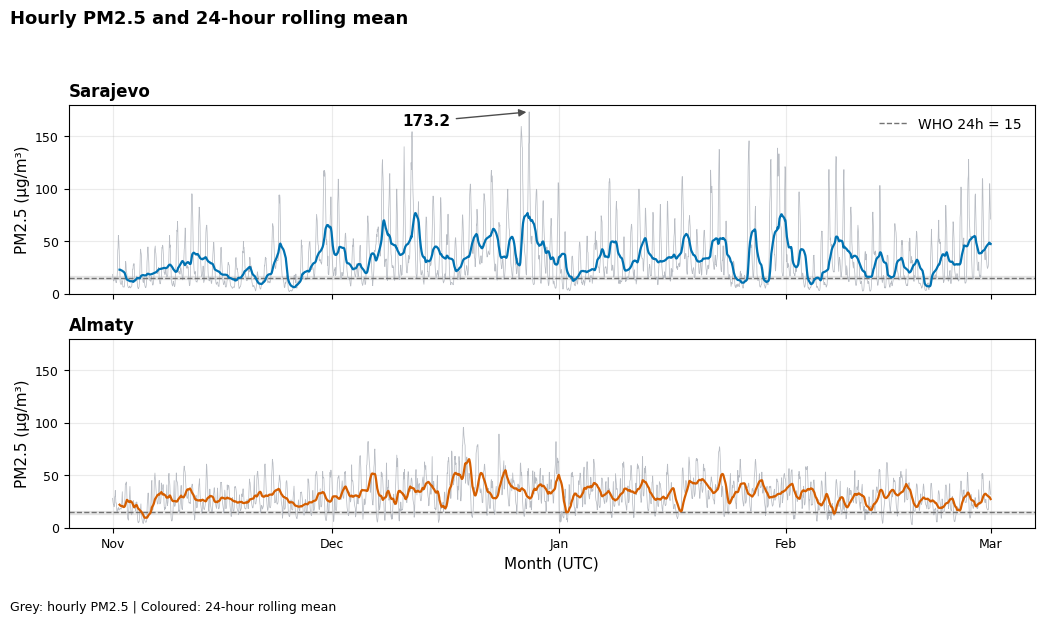

In [ ]:
from matplotlib.dates import DateFormatter, MonthLocator


def load_clean():
    df = pd.read_csv("clean_hourly.csv")
    df["time"] = pd.to_datetime(df["time"], utc=True)
    return df


def fig1_timeseries():
    df = load_clean()

    # et city order, keeping sarajevo in the first panel
    cities = df["city"].dropna().unique().tolist()

    if "Sarajevo" not in cities or len(cities) != 2:
        raise ValueError(
            f"This plot expects Sarajevo and one other city. Found: {cities}"
        )

    city_order = ["Sarajevo"] + [
        city for city in cities if city != "Sarajevo"
    ]

    city_colors = {
        city_order[0]: "#0072B2",
        city_order[1]: "#D55E00",
    }

    who = 15

    fig, axes = plt.subplots(
        2, 1,
        figsize=(10.5, 6.2),
        sharex=True,
    )

    for ax, city in zip(axes, city_order):
        g = (
            df[df["city"] == city]
            .sort_values("time")
            .copy()
        )

        # rolling mean over 24 hourly observations
        g["rolling"] = (
            g["pm2_5"]
            .rolling(24, min_periods=24)
            .mean()
        )

        ax.axhspan(
            who - 1.5, who + 1.5,
            color="#BDBDBD",
            alpha=0.30,
            zorder=0,
        )

        ax.plot(
            g["time"], g["pm2_5"],
            color="#B9BDC4",
            lw=0.55,
            zorder=1,
        )

        ax.plot(
            g["time"], g["rolling"],
            color=city_colors[city],
            lw=1.6,
            zorder=3,
        )

        ax.axhline(
            who,
            color="#737373",
            lw=1.0,
            ls="--",
            label="WHO 24h = 15",
        )

        ax.set_ylabel("PM2.5 (µg/m³)")
        ax.set_ylim(0, 180)
        ax.set_title(city, loc="left", fontweight="bold")

    # annotate Sarajevo's highest hourly reading
    sarajevo = df.loc[
        df["city"].eq("Sarajevo")
    ].dropna(subset=["time", "pm2_5"])

    if not sarajevo.empty:
        peak = sarajevo.loc[sarajevo["pm2_5"].idxmax()]

        axes[0].annotate(
            f"{peak['pm2_5']:.1f}",
            xy=(peak["time"], peak["pm2_5"]),
            xytext=(
                peak["time"] - pd.Timedelta(days=14),
                157,
            ),
            arrowprops=dict(
                arrowstyle="-|>",
                color="#4D4D4D",
                lw=1.0,
            ),
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
        )

    # one tick per month to prevent repeated month labels
    axes[1].xaxis.set_major_locator(MonthLocator(interval=1))
    axes[1].xaxis.set_major_formatter(DateFormatter("%b"))
    axes[1].set_xlabel("Month (UTC)")

    axes[0].legend(loc="upper right", frameon=False)

    fig.suptitle(
        "Hourly PM2.5 and 24-hour rolling mean",
        x=0.01,
        ha="left",
        fontsize=13,
        fontweight="bold",
    )

    fig.text(
        0.01, 0.01,
        "Grey: hourly PM2.5 | Coloured: 24-hour rolling mean",
        ha="left",
        fontsize=9,
    )

    fig.tight_layout(rect=[0, 0.05, 1, 0.94])
    fig.savefig("fig1_timeseries.png", dpi=300, bbox_inches="tight")
    plt.show()


fig1_timeseries()

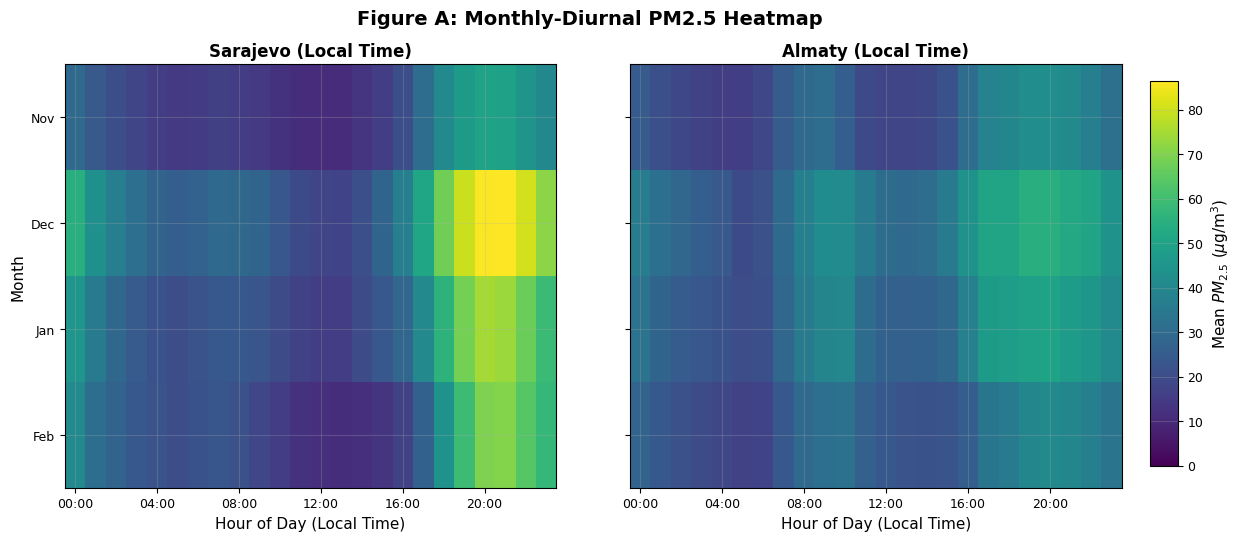

In [ ]:
# figure a: month x hour heatmap in local time with one shared colour bar
df_hourly['month'] = df_hourly['time'].dt.strftime('%b')
month_order = ['Nov', 'Dec', 'Jan', 'Feb']

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
fig.subplots_adjust(right=0.88, wspace=0.15)

matrices = {}
for city in CITIES:
    m = df_hourly[df_hourly['city'] == city].groupby(['month', 'hour'])['pm2_5'].mean()
    matrices[city] = m.unstack('hour').reindex(index=month_order, columns=range(24))
vmax = max(mat.max().max() for mat in matrices.values())

for i, city in enumerate(CITIES):
    ax = axes[i]
    im = ax.imshow(matrices[city], cmap='viridis', aspect='auto', vmin=0, vmax=vmax)
    ax.set_title(f'{city} (Local Time)', fontweight='bold')
    ax.set_xticks(range(0, 24, 4))
    ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 24, 4)])
    ax.set_xlabel('Hour of Day (Local Time)')

axes[0].set_yticks(range(4))
axes[0].set_yticklabels(month_order)
axes[0].set_ylabel('Month')

cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label(r'Mean $PM_{2.5}$ ($\mu$g/m$^3$)')

fig.suptitle('Figure A: Monthly-Diurnal PM2.5 Heatmap', fontweight='bold', y=0.98)
plt.savefig('figure_a_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

Saved fig4_episode.png


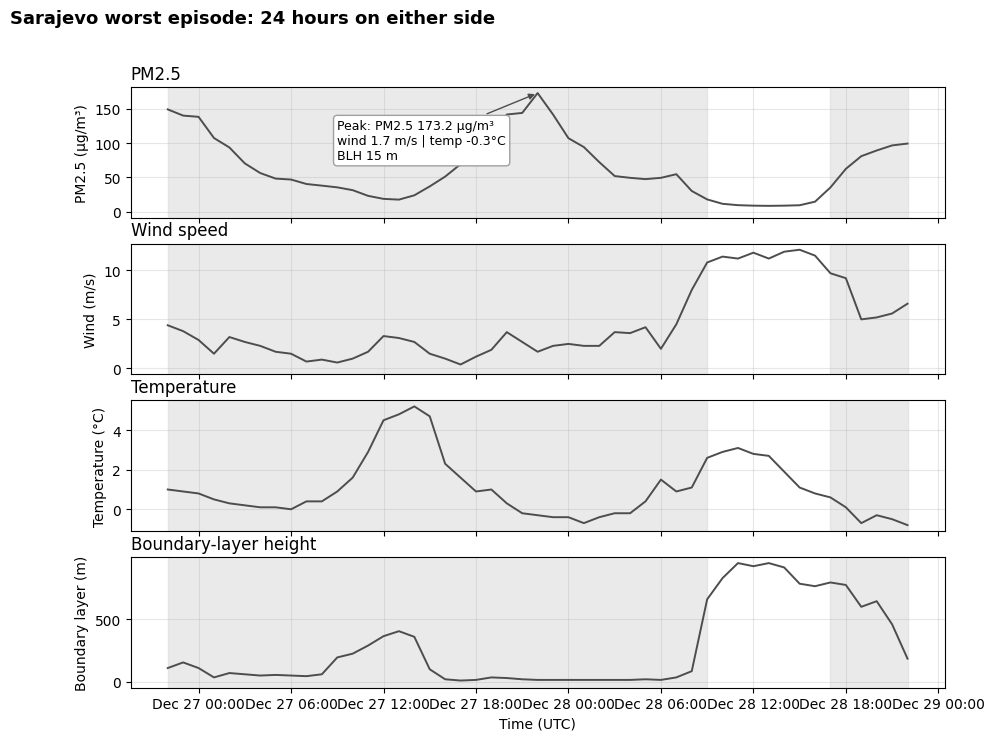

In [ ]:
# figure 4: zoom into sarajevos worst hour, 24h before and after
def fig4_episode():
    df = load_clean()
    sar = df[df["city"] == "Sarajevo"].sort_values("time")
    peak_row = sar.loc[sar["pm2_5"].idxmax()]
    peak = peak_row["time"]
    g = sar[(sar["time"] >= peak - pd.Timedelta(hours=24)) &
            (sar["time"] <= peak + pd.Timedelta(hours=24))].copy()

    fig, axes = plt.subplots(4, 1, figsize=(10.5, 7.8), sharex=True)
    specs = [
        ("pm2_5", "PM2.5 (\u00b5g/m\u00b3)", "PM2.5"),
        ("wind_speed_10m", "Wind (m/s)", "Wind speed"),
        ("temperature_2m", "Temperature (\u00b0C)", "Temperature"),
        ("boundary_layer_height", "Boundary layer (m)", "Boundary-layer height"),
    ]
    for ax, (col, ylabel, title) in zip(axes, specs):
        ax.axvspan(peak - pd.Timedelta(hours=24), peak + pd.Timedelta(hours=24),
                   color="none")
        # grey shading where pm2.5 is above the who limit
        mask = g["pm2_5"] > WHO
        ax.fill_between(g["time"], ax.get_ylim()[0] if ax.has_data() else 0, 1,
                        where=mask, color="#D9D9D9", alpha=0.55, transform=ax.get_xaxis_transform())
        ax.plot(g["time"], g[col], color="#4D4D4D", lw=1.4)
        ax.set_ylabel(ylabel)
        ax.set_title(title, loc="left")
    peak_y = peak_row["pm2_5"]
    axes[0].annotate(
        f"Peak: PM2.5 {peak_y:.1f} \u00b5g/m\u00b3\n"
        f"wind {peak_row['wind_speed_10m']:.1f} m/s | "
        f"temp {peak_row['temperature_2m']:.1f}\u00b0C\n"
        f"BLH {peak_row['boundary_layer_height']:.0f} m",
        xy=(peak, peak_y), xytext=(peak - pd.Timedelta(hours=13), peak_y - 38),
        arrowprops=dict(arrowstyle="-|>", color="#4D4D4D"),
        fontsize=9, ha="left", va="top",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#A0A0A0"))
    axes[-1].xaxis.set_major_formatter(DateFormatter("%b %d %H:%M"))
    axes[-1].set_xlabel("Time (UTC)")
    fig.suptitle("Sarajevo worst episode: 24 hours on either side",
                 x=0.01, ha="left", fontsize=13, fontweight="bold")

    save(fig, "fig4_episode.png")





fig4_episode()

In [ ]:
# reload the clean data and set shared plot settings for the final figures
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.titlesize": 14,
    "grid.alpha": 0.25
})

df_hourly = pd.read_csv("clean_hourly.csv", parse_dates=["time"])
df_daily = pd.read_csv("clean_daily.csv", parse_dates=["date"])

CITIES = ["Sarajevo", "Almaty"]
COLORS = {"Sarajevo": "#440154", "Almaty": "#22A884"}
WHO_LIMIT = 15

print("Loaded hourly shape:", df_hourly.shape)
print("Loaded daily shape:", df_daily.shape)

Loaded hourly shape: (5760, 56)
Loaded daily shape: (240, 15)


In [ ]:
# reload data and print the details of sarajevos worst hour
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.titlesize': 14,
    'grid.alpha': 0.25
})

CITIES = ['Sarajevo', 'Almaty']
COLORS = {'Sarajevo': '#440154', 'Almaty': '#22A884'}
WHO_LIMIT = 15

df_hourly = pd.read_csv('clean_hourly.csv', parse_dates=['time'])
df_daily = pd.read_csv('clean_daily.csv', parse_dates=['date'])

sar_hourly_sort = df_hourly[df_hourly['city'] == 'Sarajevo'].sort_values('pm2_5', ascending=False)
print('Sarajevo Peak Hour Details:')
print(sar_hourly_sort[['time', 'pm2_5', 'wind_speed_10m', 'temperature_2m', 'boundary_layer_height']].head(1))

Sarajevo Peak Hour Details:
                    time  pm2_5  wind_speed_10m  temperature_2m  \
1366 2025-12-27 22:00:00  173.2             1.7            -0.3   

      boundary_layer_height  
1366                   15.0  


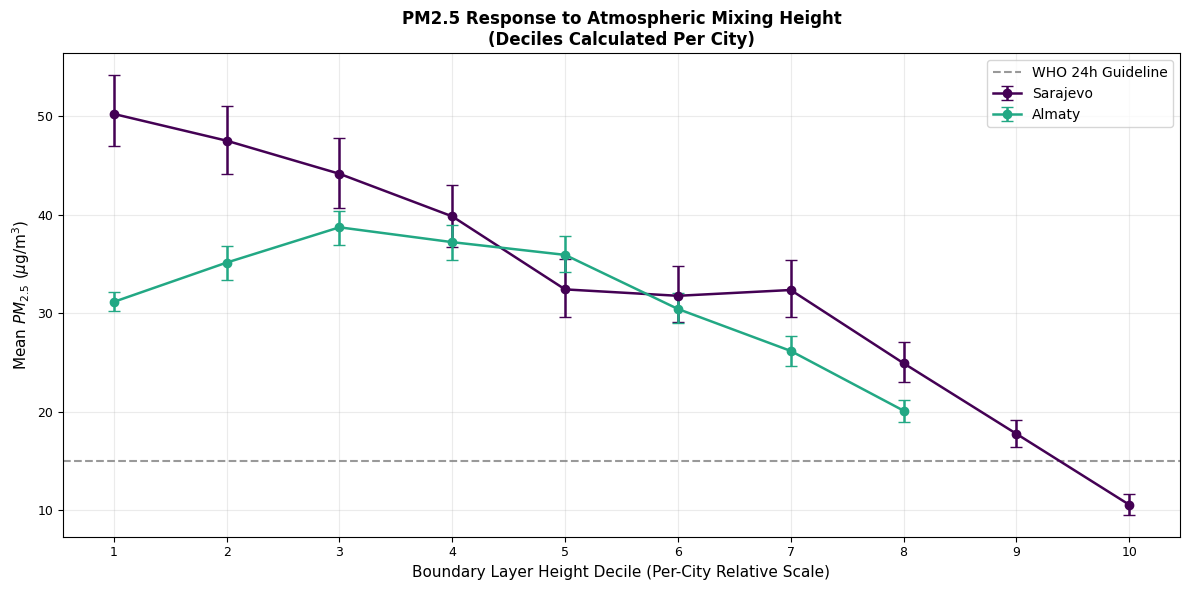

In [ ]:
# figure b: how pm2.5 changes with mixing height (blh) and wind
# bootstrap confidence interval for the mean (500 resamples)

def bootstrap_ci_clean(s, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    arr = s.dropna().to_numpy()

    if len(arr) == 0:
        return np.nan, np.nan, np.nan

    boots = rng.choice(
        arr, size=(n_boot, len(arr)), replace=True
    ).mean(axis=1)

    return arr.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


df_hourly['blh_decile'] = df_hourly.groupby('city')[
    'boundary_layer_height'
].transform(
    lambda x: pd.qcut(x, q=10, labels=False, duplicates='drop') + 1
)

fig, ax = plt.subplots(figsize=(12, 6))

for city in CITIES:
    g = df_hourly[df_hourly['city'] == city]
    deciles = sorted(g['blh_decile'].dropna().unique())

    means, lows, highs = [], [], []

    for dec in deciles:
        m, l, h = bootstrap_ci_clean(
            g.loc[g['blh_decile'] == dec, 'pm2_5']
        )
        means.append(m)
        lows.append(l)
        highs.append(h)

    means = np.array(means)

    ax.errorbar(
        deciles,
        means,
        yerr=[means - np.array(lows), np.array(highs) - means],
        fmt='o-',
        label=city,
        color=COLORS[city],
        capsize=4,
        lw=1.8
    )

ax.axhline(
    WHO_LIMIT,
    ls='--',
    color='gray',
    alpha=0.8,
    label='WHO 24h Guideline'
)

ax.set_xlabel('Boundary Layer Height Decile (Per-City Relative Scale)')
ax.set_ylabel(r'Mean $PM_{2.5}$ ($\mu$g/m$^3$)')
ax.set_title(
    'PM2.5 Response to Atmospheric Mixing Height\n'
    '(Deciles Calculated Per City)',
    fontweight='bold'
)
ax.set_xticks(range(1, 11))
ax.legend()

fig.tight_layout()
fig.savefig('figure_b_meteorology.png', dpi=150, bbox_inches='tight')
plt.show()

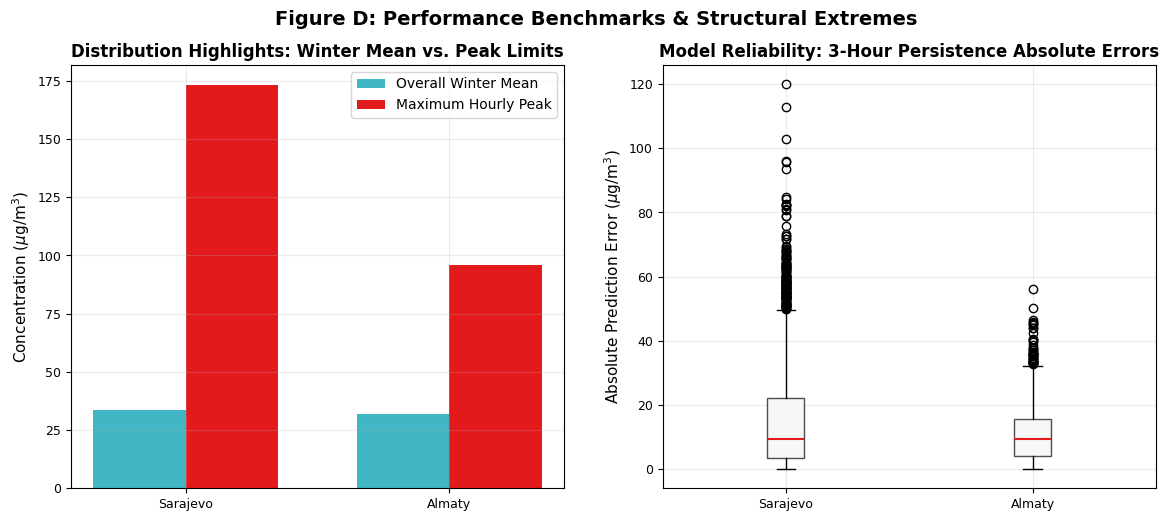

In [ ]:
# figure d: winter mean vs peak bars, plus the 3h persistence errors as boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

summary_data = df_hourly.groupby('city')['pm2_5'].agg(['mean', 'max']).reindex(CITIES)
x = np.arange(len(CITIES))
width = 0.35

axes[0].bar(x - width/2, summary_data['mean'], width, label='Overall Winter Mean', color='#41b6c4')
axes[0].bar(x + width/2, summary_data['max'], width, label='Maximum Hourly Peak', color='#e31a1c')
axes[0].set_ylabel(r'Concentration ($\mu$g/m$^3$)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(CITIES)
axes[0].set_title('Distribution Highlights: Winter Mean vs. Peak Limits', fontweight='bold')
axes[0].legend()

# persistence forecast = value from 3 hours earlier, per city
df_hourly['pm25_pred_3h'] = df_hourly.groupby('city')['pm2_5'].shift(3)
df_hourly['forecast_error'] = (df_hourly['pm25_pred_3h'] - df_hourly['pm2_5']).abs()

errors_list = [df_hourly[df_hourly['city'] == city]['forecast_error'].dropna() for city in CITIES]
axes[1].boxplot(errors_list, tick_labels=CITIES, patch_artist=True,
                boxprops=dict(facecolor='#f7f7f7', color='#4d4d4d'),
                medianprops=dict(color='#e31a1c', lw=1.5))
axes[1].set_ylabel(r'Absolute Prediction Error ($\mu$g/m$^3$)')
axes[1].set_title('Model Reliability: 3-Hour Persistence Absolute Errors', fontweight='bold')

fig.suptitle('Figure D: Performance Benchmarks & Structural Extremes', fontweight='bold', y=0.98)
plt.savefig('figure_d_summary_and_baseline.png', dpi=150, bbox_inches='tight')
plt.show()

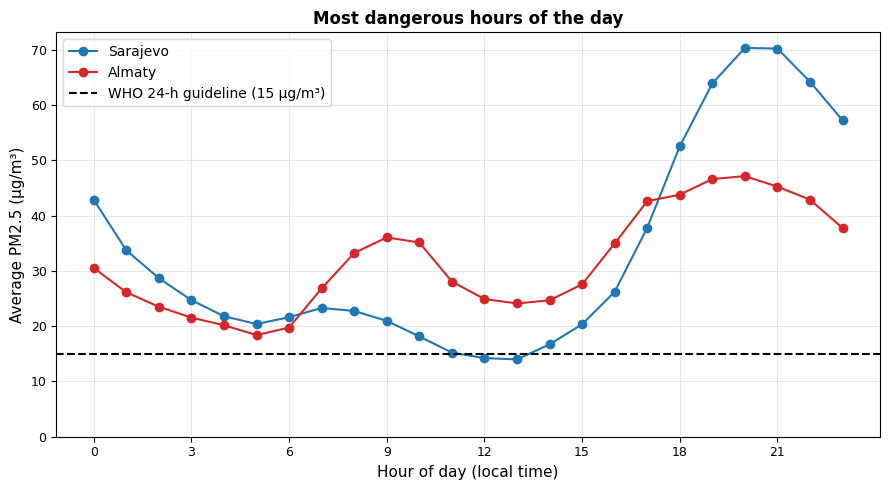

In [ ]:
df = pd.read_csv("clean_hourly.csv", parse_dates=["time"])
df["hour"] = df["time"].dt.hour

COLORS = {"Sarajevo": "#1f77b4", "Almaty": "#d62728"}

# map raw features to clean labels
FEATURES = {
    "carbon_monoxide": "CO", "nitrogen_dioxide": "NO2", "sulphur_dioxide": "SO2",
    "relative_humidity_2m": "Humidity", "pressure_msl": "Pressure",
    "snow_depth": "Snow depth", "precipitation": "Precipitation",
    "temperature_2m": "Temperature", "wind_speed_10m": "Wind speed",
    "shortwave_radiation": "Sunlight", "boundary_layer_height": "Boundary layer height",
    "ozone": "Ozone",
}

# initialize diurnal line plot
fig1, ax1 = plt.subplots(figsize=(9, 5))

# plot hourly pm2.5 profile for each city
for city, color in COLORS.items():
    hourly_mean = df[df["city"] == city].groupby("hour")["pm2_5"].mean()
    ax1.plot(hourly_mean.index, hourly_mean.values, marker="o", color=color, label=city)

# add target reference line
ax1.axhline(15, color="black", linestyle="--", label="WHO 24-h guideline (15 µg/m³)")
# set axis titles and ranges
ax1.set_title("Most dangerous hours of the day", fontweight="bold")
ax1.set_xlabel("Hour of day (local time)")
ax1.set_ylabel("Average PM2.5 (µg/m³)")
ax1.set_xticks(range(0, 24, 3))
ax1.set_ylim(bottom=0)
ax1.grid(alpha=0.3)
ax1.legend()

plt.tight_layout()
plt.savefig("dangerous_hours.png", dpi=150)
plt.show()

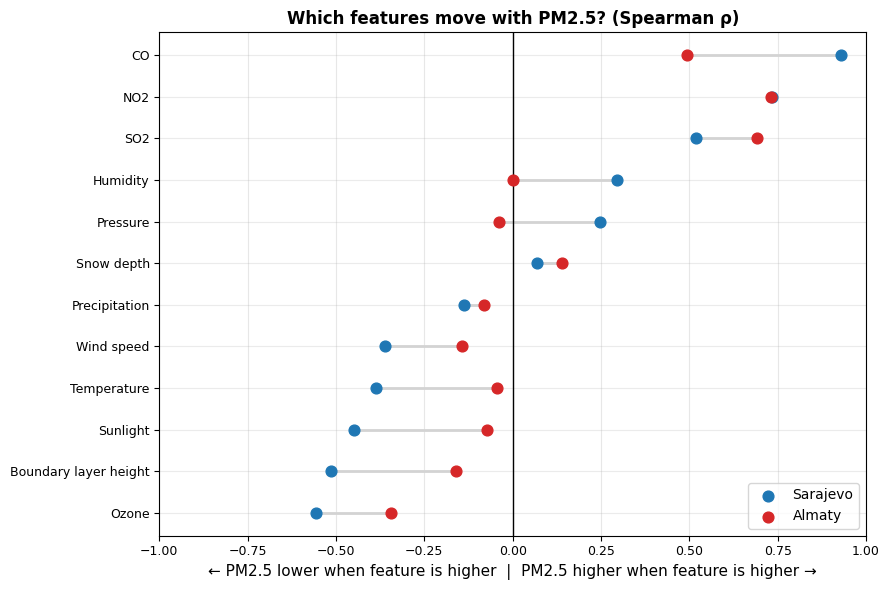

In [ ]:
# spearman correlation of every feature with pm2.5, done separately for each city
corr = pd.DataFrame({
    city: df[df["city"] == city][list(FEATURES)].corrwith(df[df["city"] == city]["pm2_5"],
                                                          method="spearman")
    for city in COLORS
})
# swap column names for short readable labels
corr.index = [FEATURES[c] for c in corr.index]
# sort by sarajevo so the strongest links end up at the top and bottom
corr = corr.sort_values("Sarajevo")

fig2, ax2 = plt.subplots(figsize=(9, 6))

# dumbbell chart so a grey line joins the two cities for each feature
y = range(len(corr))
ax2.hlines(y, corr["Sarajevo"], corr["Almaty"], color="lightgrey", linewidth=2)
for city, color in COLORS.items():
    ax2.scatter(corr[city], y, color=color, s=60, label=city, zorder=3)

# line at 0 splits negative and positive links
ax2.axvline(0, color="black", linewidth=1)
ax2.set_yticks(y)
ax2.set_yticklabels(corr.index)
ax2.set_xlim(-1, 1)
ax2.set_title("Which features move with PM2.5? (Spearman ρ)", fontweight="bold")
ax2.set_xlabel("← PM2.5 lower when feature is higher  |  PM2.5 higher when feature is higher →")
ax2.grid(axis="x", alpha=0.3)
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig("pm25_drivers.png", dpi=150)
plt.show()


# **Poor plotting examples**

Saved abandoned_v1.png


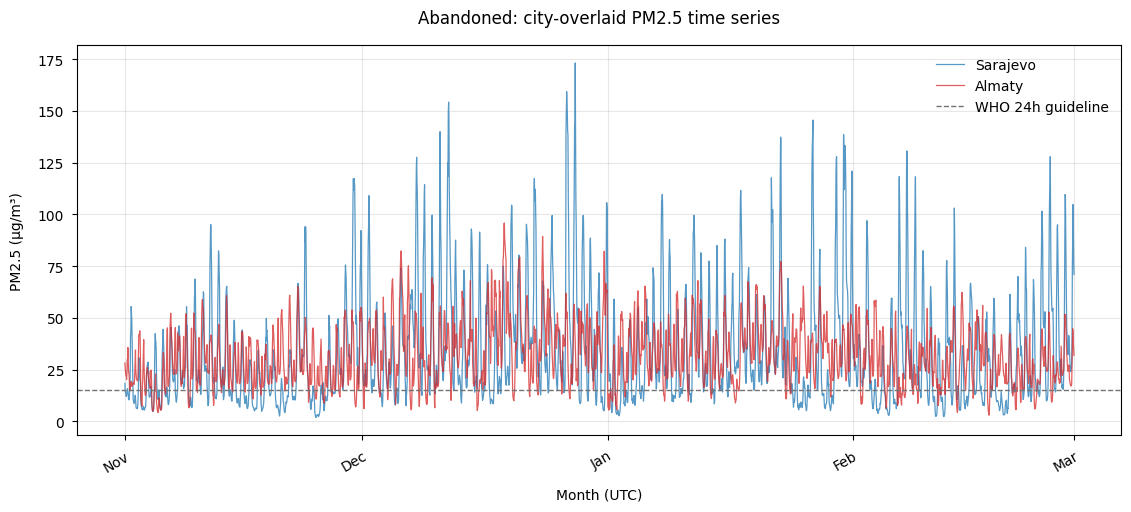

In [ ]:
# abandoned attempt 1: both cities on one plot. way too cluttered, the lines overlap and you cant see almatys pattern.
# red/blue is also not great for colourblind people. replaced by the two panel version (figure 1)
def abandoned_v1():
    df = load_clean()

    fig, ax = plt.subplots(figsize=(12, 6))
    fig.subplots_adjust(
        left=0.10,
        right=0.97,
        bottom=0.23,
        top=0.88
    )

    for city in CITY_ORDER:
        g = df[df["city"] == city].sort_values("time")
        ax.plot(
            g["time"], g["pm2_5"],
            lw=0.9, alpha=0.75,
            color=COLORS[city], label=city
        )

    ax.axhline(
        WHO, color="#737373", lw=1.0, ls="--",
        label="WHO 24h guideline"
    )
    ax.set_title(
        "Abandoned: city-overlaid PM2.5 time series",
        pad=16
    )
    ax.set_ylabel("PM2.5 (µg/m³)", labelpad=10)
    ax.set_xlabel("Month (UTC)", labelpad=10)
    ax.tick_params(axis="both", labelsize=10, pad=6)
    ax.legend(frameon=False, fontsize=10)

    ax.xaxis.set_major_locator(
        plt.matplotlib.dates.AutoDateLocator(minticks=4, maxticks=8)
    )
    ax.xaxis.set_major_formatter(DateFormatter("%b"))

    plt.setp(
        ax.get_xticklabels(),
        rotation=30,
        ha="right",
        rotation_mode="anchor"
    )

    save(fig, "abandoned_v1.png")




abandoned_v1()


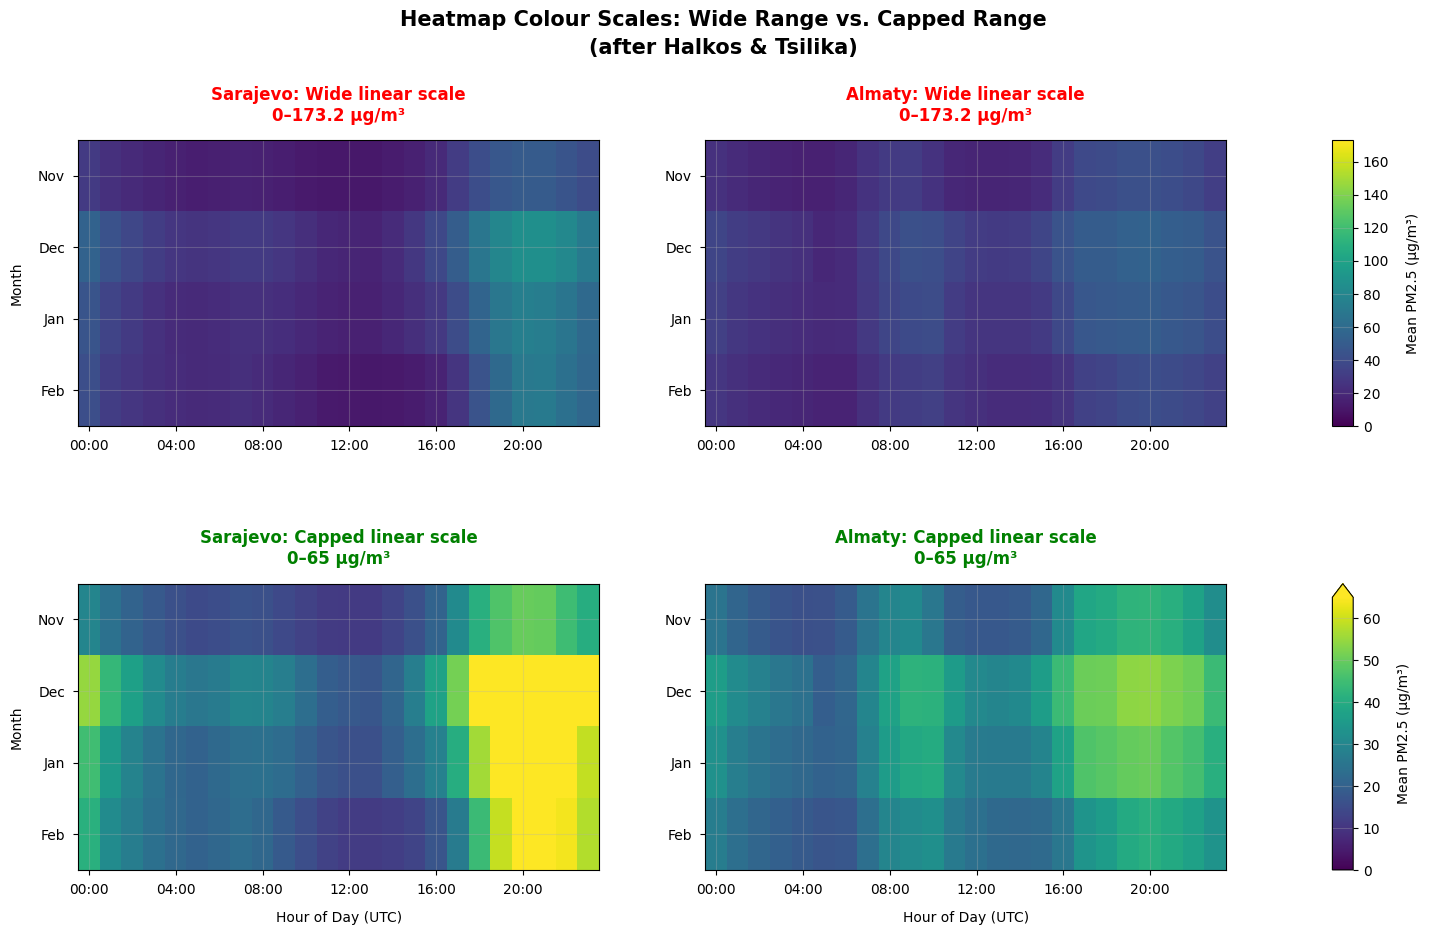

In [ ]:
# abandoned attempt 2: heatmap with a wide colour scale (0-173). one extreme hour stretches the scale
# so nearly everything looks dark purple. capped it at 65 instead so the daily pattern shows
df = pd.read_csv("clean_hourly.csv", parse_dates=["time"])
df["month"] = df["time"].dt.strftime("%b")
df["hour"] = df["time"].dt.hour

months = ["Nov", "Dec", "Jan", "Feb"]
cities = ["Sarajevo", "Almaty"]

matrices = {
    city: (
        df[df["city"] == city]
        .groupby(["month", "hour"])["pm2_5"]
        .mean()
        .unstack("hour")
        .reindex(index=months, columns=range(24))
    )
    for city in cities
}

# two heatmap columns and a separate colourbar column
fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(
    2, 3,
    width_ratios=[1, 1, 0.04],
    hspace=0.55,
    wspace=0.30
)
fig.subplots_adjust(left=0.07, right=0.92, bottom=0.10, top=0.83)

scales = [
    (173.2, "Wide linear scale", "red"),
    (65.0, "Capped linear scale", "green")
]

for row, (vmax, label, title_color) in enumerate(scales):
    for col, city in enumerate(cities):
        ax = fig.add_subplot(gs[row, col])

        im = ax.imshow(
            matrices[city],
            cmap="viridis",
            aspect="auto",
            vmin=0,
            vmax=vmax
        )

        ax.set_title(
            f"{city}: {label}\n0–{vmax:g} µg/m³",
            color=title_color,
            fontweight="bold",
            fontsize=12,
            pad=14
        )

        ax.set_xticks(range(0, 24, 4))
        ax.set_xticklabels(
            [f"{hour:02d}:00" for hour in range(0, 24, 4)]
        )
        ax.set_yticks(range(len(months)))
        ax.set_yticklabels(months)
        ax.tick_params(labelsize=10, pad=6)

        if col == 0:
            ax.set_ylabel("Month", labelpad=10)

        if row == 1:
            ax.set_xlabel("Hour of Day (UTC)", labelpad=10)

    # one colourbar per row
    cbar_ax = fig.add_subplot(gs[row, 2])
    cbar = fig.colorbar(
        im,
        cax=cbar_ax,
        extend="max" if row == 1 else "neither"
    )
    cbar.set_label("Mean PM2.5 (µg/m³)", labelpad=12)

fig.suptitle(
    "Heatmap Colour Scales: Wide Range vs. Capped Range\n"
    "(after Halkos & Tsilika)",
    fontsize=15,
    fontweight="bold",
    y=0.96,
    linespacing=1.5
)

plt.show()

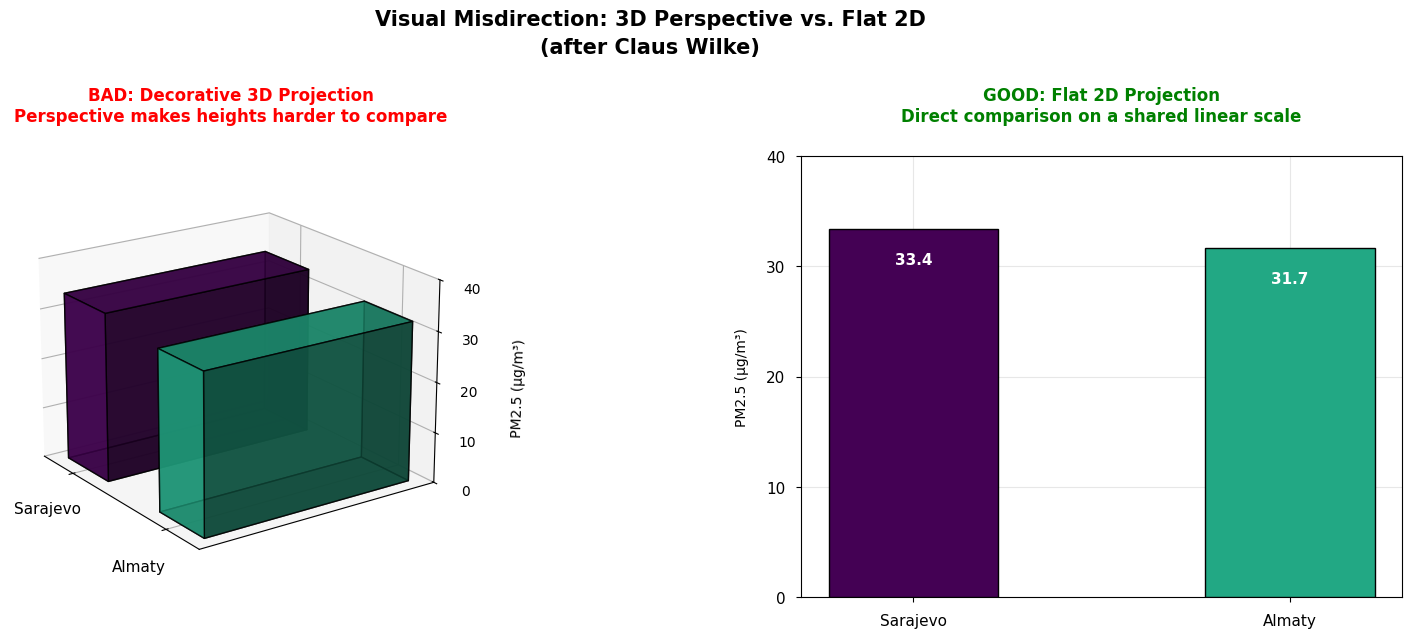

In [ ]:
# bad vs good example: 3d bars make heights hard to compare
import numpy as np
import matplotlib.pyplot as plt

categories = ['Sarajevo', 'Almaty']
values = [33.4, 31.7]
colors = ['#440154', '#22A884']

fig = plt.figure(figsize=(16, 7))

# extra space between panels and below the main title
fig.subplots_adjust(
    left=0.05,
    right=0.97,
    bottom=0.12,
    top=0.75,
    wspace=0.45
)

# --- left panel: 3d projection ---
ax_3d = fig.add_subplot(1, 2, 1, projection='3d')

x_pos = np.arange(len(categories))
y_pos = np.zeros(len(categories))
z_pos = np.zeros(len(categories))

dx = 0.45
dy = 0.45

ax_3d.bar3d(
    x_pos, y_pos, z_pos,
    dx, dy, values,
    color=colors,
    alpha=0.8,
    edgecolor='black'
)

ax_3d.set_xticks(x_pos + dx / 2)
ax_3d.set_xticklabels(categories, fontsize=11)
ax_3d.tick_params(axis='x', pad=10)
ax_3d.tick_params(axis='z', pad=5)

ax_3d.set_zlim(0, 40)
ax_3d.set_zticks(range(0, 41, 10))
ax_3d.set_yticks([])

ax_3d.view_init(elev=20, azim=-35)
ax_3d.set_zlabel("PM2.5 (µg/m³)", labelpad=12)

ax_3d.set_title(
    "BAD: Decorative 3D Projection\n"
    "Perspective makes heights harder to compare",
    color='red',
    fontweight='bold',
    fontsize=12,
    pad=25
)

ax_2d = fig.add_subplot(1, 2, 2)

bars = ax_2d.bar(
    categories,
    values,
    color=colors,
    width=0.45,
    edgecolor='black',
    zorder=3
)

ax_2d.set_ylim(0, 40)
ax_2d.set_yticks(range(0, 41, 10))
ax_2d.set_ylabel("PM2.5 (µg/m³)", labelpad=12)
ax_2d.tick_params(axis='both', labelsize=11, pad=8)

ax_2d.set_title(
    "GOOD: Flat 2D Projection\n"
    "Direct comparison on a shared linear scale",
    color='green',
    fontweight='bold',
    fontsize=12,
    pad=25
)

for bar in bars:
    height = bar.get_height()
    ax_2d.text(
        bar.get_x() + bar.get_width() / 2,
        height - 3.5,
        f"{height:.1f}",
        ha='center',
        va='bottom',
        color='white',
        fontweight='bold',
        fontsize=11
    )

fig.suptitle(
    "Visual Misdirection: 3D Perspective vs. Flat 2D\n"
    "(after Claus Wilke)",
    fontsize=15,
    fontweight='bold',
    y=0.96,
    linespacing=1.5
)

plt.show()